PNN Accuracy: 57.50%
GRNN RMSE: 1816.02
GRNN R2: 0.4781
Sample 1: Duration=18, Age=42, Installment=4
  PNN: REJECTED (Prob: 48.3%)
  GRNN: Blocked (High Risk)
Sample 2: Duration=36, Age=29, Installment=3
  PNN: REJECTED (Prob: 42.4%)
  GRNN: Blocked (High Risk)
Sample 3: Duration=48, Age=48, Installment=2
  PNN: REJECTED (Prob: 42.2%)
  GRNN: Blocked (High Risk)


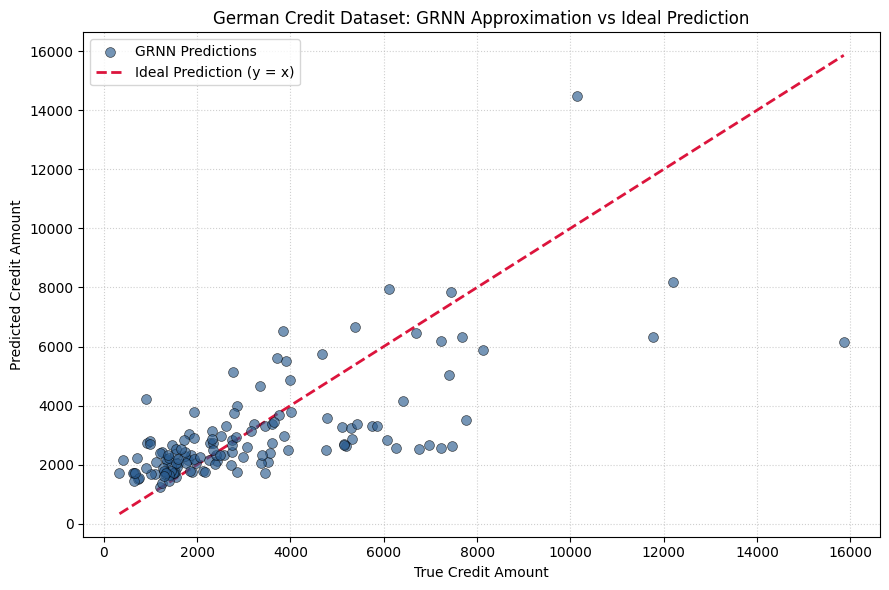

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)


class ProbabilisticNeuralNetwork:
    def __init__(self, sigma=1.0):
        self.sigma = sigma
        self.patterns = None
        self.labels = None

    def fit(self, X, y):
        self.patterns = np.array(X)
        self.labels = np.array(y)

    def predict_proba(self, X):
        X = np.array(X)
        probas = []
        classes = np.unique(self.labels)

        for x in X:
            densities = {}
            for c in classes:
                pts = self.patterns[self.labels == c]
                dists = np.linalg.norm(pts - x, axis=1)
                kernels = np.exp(-(dists**2) / (2 * (self.sigma**2)))
                densities[c] = np.sum(kernels) / len(pts)

            total = sum(densities.values())
            if total > 0:
                normalized = {c: densities[c] / total for c in classes}
            else:
                normalized = {c: 1.0 / len(classes) for c in classes}
            probas.append(normalized)
        return probas

    def predict(self, X):
        probas = self.predict_proba(X)
        return np.array([max(p, key=p.get) for p in probas])


class GeneralizedRegressionNeuralNetwork:
    def __init__(self, sigma=1.0):
        self.sigma = sigma
        self.patterns = None
        self.targets = None

    def fit(self, X, y):
        self.patterns = np.array(X)
        self.targets = np.array(y)

    def predict(self, X):
        X = np.array(X)
        preds = []

        for x in X:
            dists = np.linalg.norm(self.patterns - x, axis=1)
            weights = np.exp(-(dists**2) / (2 * (self.sigma**2)))
            sum_weights = np.sum(weights)

            if sum_weights > 0:
                pred = np.sum(weights * self.targets) / sum_weights
            else:
                pred = np.mean(self.targets)
            preds.append(pred)
        return np.array(preds)


credit_data = fetch_openml(
    name="credit-g", version=1, as_frame=True, parser="auto")
df = credit_data.frame

feature_cols = ["duration", "age", "installment_commitment", "residence_since"]

X_raw = df[feature_cols].values
y_class_raw = (df["class"] == "good").astype(int).values
y_amount_raw = df["credit_amount"].values
(
    X_train_raw,
    X_test_raw,
    y_class_train,
    y_class_test,
    y_amount_train,
    y_amount_test,
) = train_test_split(
    X_raw,
    y_class_raw,
    y_amount_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_class_raw,
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

pnn = ProbabilisticNeuralNetwork(sigma=0.9)
pnn.fit(X_train, y_class_train)

y_class_pred = pnn.predict(X_test)
acc = accuracy_score(y_class_test, y_class_pred)
print(f"PNN Accuracy: {acc * 100:.2f}%")

train_approved_mask = y_class_train == 1
X_train_approved = X_train[train_approved_mask]
y_amount_train_approved = y_amount_train[train_approved_mask]

grnn = GeneralizedRegressionNeuralNetwork(sigma=0.6)
grnn.fit(X_train_approved, y_amount_train_approved)

test_approved_mask = y_class_test == 1
X_test_approved = X_test[test_approved_mask]
y_amount_test_approved = y_amount_test[test_approved_mask]

y_amount_pred = grnn.predict(X_test_approved)

rmse = np.sqrt(mean_squared_error(y_amount_test_approved, y_amount_pred))
r2 = r2_score(y_amount_test_approved, y_amount_pred)

print(f"GRNN RMSE: {rmse:.2f}")
print(f"GRNN R2: {r2:.4f}")

probas = pnn.predict_proba(X_test[:3])

for i in range(3):
    orig = X_test_raw[i]
    is_good = y_class_pred[i] == 1
    prob_good = probas[i][1] * 100
    print(f"Sample {i+1}: Duration={orig[0]}, Age={orig[1]}, Installment={orig[2]}")
    print(f"  PNN: {'APPROVED' if is_good else 'REJECTED'} (Prob: {prob_good:.1f}%)")

    if is_good:
        predicted_amount = grnn.predict([X_test[i]])[0]
        actual_amount = y_amount_test[i]
        print(f"  GRNN: Pred={predicted_amount:.0f}, Actual={actual_amount:.0f}")
    else:
        print("  GRNN: Blocked (High Risk)")

plt.figure(figsize=(9, 6))

plt.scatter(
    y_amount_test_approved,
    y_amount_pred,
    color="#2b5c8f",
    alpha=0.65,
    edgecolors="black",
    linewidths=0.5,
    s=50,
    label="GRNN Predictions",
    zorder=3,
)

axis_min = min(y_amount_test_approved.min(), y_amount_pred.min())
axis_max = max(y_amount_test_approved.max(), y_amount_pred.max())

plt.plot(
    [axis_min, axis_max],
    [axis_min, axis_max],
    linestyle="--",
    color="crimson",
    linewidth=2,
    label="Ideal Prediction (y = x)",
    zorder=2,
)

plt.title("German Credit Dataset: GRNN Approximation vs Ideal Prediction")
plt.xlabel("True Credit Amount")
plt.ylabel("Predicted Credit Amount")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()